In [159]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Markdown as MD
from numpy.linalg import norm
# Carregando dataset
with h5py.File('Data.hdf5') as f:
    A = f['A'][:]
    B = f['B'][:]
    G = f['G'][:]

F = np.array(Image.open('original.jpeg'))

def mdisp(arg): #Função auxiliar para realizar print com markdown
    display(MD(arg))

def vec(x:np.ndarray):
    x = np.atleast_2d(x)
    return x.reshape(np.prod(x.shape),1,order='F').squeeze()

## O problema inverso
Como apresentado em etapas anteriores,uma imagem borrada $\mathbf{G}$ é uma convolução de uma PSF(*Point Spread Function*), representada por $\mathbf{P}$, com uma imagem nítida $\mathbf{F}$, que eu quero determinar
$$
\mathbf{G} = \mathbf{P} \ast \mathbf{F},
$$
em que $\mathbf{G}$, $\mathbf P$ e $\mathbf{F}$ possuem $\sqrt{n}\times \sqrt{n}$ elementos.

## A convolução em sistema linear
Em sistema linear, a equação se torna
$$
\mathbf{g} = \mathbf{K}\mathbf{f},
$$
em que:
- $\mathbf{g} = \mathrm{vec}(\mathbf{G})$
- $\mathbf{f} = \mathrm{vec}(\mathbf{F})$
- $\mathbf{K}_{n\times n} = \mathrm{toep2}(\mathbf{P}_{\sqrt{n}\times\sqrt{n}})$

- O operador $\mathrm{vec}$ empilha uma matriz 2D em um vetor coluna
- O operador $\mathrm{toep2}$ transforma uma matriz em duas dimensões em uma matriz **BTTB**(Bloco Toeplitz com blocos Toeplitz)

### Mal condicionamento
- $\mathbf{K}$ apresenta número de condição elevado;
- $\mathbf{G}$ é corrompido por ruído; e
- As dimensões de $\mathbf{K}$ crescem quadráticamente com as dimensões de $\mathbf P$.

**O problema é mal posto**

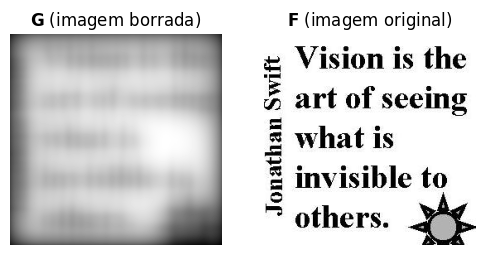

In [160]:
plt.figure(figsize=(6,3))
ax = plt.subplot(1,2,1)
plt.imshow(G.T,cmap='gray')
plt.title(r'$\mathbf{G}$ (imagem borrada)')
ax.set_axis_off()
ax= plt.subplot(1,2,2)
plt.imshow(F,cmap='gray')
plt.title(r'$\mathbf{F}$ (imagem original)')
ax.set_axis_off()

## Poupando espaço na memória
Tipos específicos de PSFs podem ser representadas por meio de um produto de Kronecker, evitando alocação explícita de $\mathbf{K}$
$$
\mathbf K = \mathbf{A} \otimes \mathbf{B} = 
\begin{bmatrix}
    a_{11}\mathbf{B} & \ldots & a_{1m}\mathbf{B}\\
    \vdots & \ddots & \vdots\\
    a_{m1}\mathbf{B}&\ldots & a_{mm}\mathbf{B}
\end{bmatrix}
$$

A SVD de $\mathbf{K}$ pode ser representada pela SVD de $\mathbf{A}$ e $\mathbf{B}$ por meio de
$$
\mathbf{K}_{n\times n } = \mathbf{U}\Sigma \mathbf{V}^\mathrm{T} = (\mathbf{U}_A \otimes \mathbf{U}_B) (\Sigma_A \otimes \Sigma_B) (\mathbf{V}_A \otimes \mathbf{V}_B)^\mathrm{T}
$$
em que:
- $\mathbf{A}_{\sqrt{n}\times\sqrt{n}} = \mathbf{U}_A \Sigma_A \mathbf{V}_A^\mathrm{T}$ e 
- $\mathbf{B}_{\sqrt{n}\times\sqrt{n}} = \mathbf{U}_B\Sigma_B \mathbf{V}_B^\mathrm{T}$

Note que computar $(\mathbf{U}_A\otimes\mathbf{U}_B)$ e $(\mathbf{V}_A\otimes\mathbf{V}_B)$ diretamente apresentam o mesmo problema de alocar $\mathbf{K}$, gerando matrizes de dimensões $n\times n$. No entanto, o produto de Kronecker possui a seguinte identidade
$$
(\mathbf{L} \otimes \mathbf{R})\space\mathrm{vec}(\mathbf V) = \mathrm{vec}(\mathbf R\space \mathbf V\space \mathbf{ L}^\mathrm{T}),
$$
o que permite resolver o problema utilizando apenas multiplicações de matrizes $\sqrt{n}\times\sqrt{n}$.

## Computando o problema direto
como $\mathbf{g}$ é
$$
\mathbf{g} = \mathbf{K}\mathbf{f} = (\mathbf{A}\otimes\mathbf{B})\mathrm{vec}(\mathbf{F}),
$$
o problema direto se torna
$$
\mathrm{vec}(\mathbf{G})= \mathrm{vec}(\mathbf{B}\space \mathbf{F}\space\mathbf{A}^\mathrm{T})\\
\mathbf{G}=\mathbf{B}\space \mathbf{F}\space\mathbf{A}^\mathrm{T}.
$$
Como $\mathbf{B}$, $\mathbf{A}$, e $\mathbf{F}$ possuem dimensões $\sqrt{n}\times\sqrt{n}$, essa mudança reduz significativamente o custo da operação.

### Exemplo: Um delta de Kronecker
Podemos gerar um delta de kronecker(uma imagem com um único pixel diferente de zero) como dado de entrada, permitindo estimar a PSF que borrou a imagem do dataset.
$$
\mathbf{F}_\delta = 
\begin{bmatrix}
    0   &   \dots   &   0   &   \dots   &    0\\
    \vdots&\vdots&\vdots&\vdots&\vdots\\
    0&\dots&1&\dots&0\\
    \vdots&\vdots&\vdots&\vdots&\vdots\\
    0   &   \dots   &   0   &   \dots   &    0\\
\end{bmatrix},\\
\mathbf{P} = \mathbf{B} \mathbf{F}_\delta \mathbf{A}^\mathrm{T}

$$

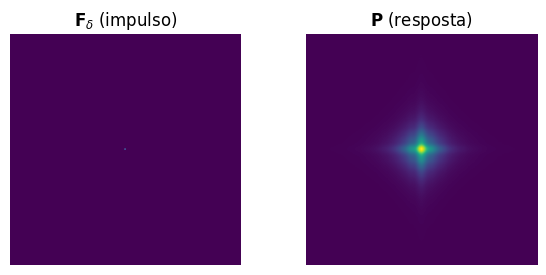

In [161]:
F_delta = np.zeros(G.shape) #Dk é delta de kronecker
mid_idx = ((np.asarray(F_delta.shape)-1)/2).astype(int)
F_delta[mid_idx,mid_idx] = 1

P = ( B @ F_delta ) @ A.T

matrices = [F_delta,P]
titles = [r'$\mathbf{F}_\delta$ (impulso)',r'$\mathbf{P}$ (resposta)']
plt.figure(figsize=(7,3))
for idx,(M,title) in enumerate(zip(matrices,titles)):
    ax = plt.subplot(1,2,idx+1)
    ax.imshow(M)
    ax.set_title(title)
    ax.set_axis_off()

### Completando a volta: recomputando $\mathbf{A}$ e $\mathbf{B}$
Kamm e Nagy [2] mostram que se uma PSF pode ser representada como $\mathbf{P} = \sigma \mathbf{u}\mathbf{v}^\mathrm{T}$ ($\mathrm{rank}(\mathbf{P}) = 1$), as matrizes que compõem $\mathbf{K}$ são dadas por:
- $\mathbf{A} = \mathrm{toep}(\sqrt{\sigma \mathbf{u}})$
- $\mathbf{B} = \mathrm{toep}(\sqrt{\sigma \mathbf{v}})$

In [173]:
print(f"rank(P) = {np.linalg.matrix_rank(P)}")
u,s,v = np.linalg.svd(P)
v = v.T

rank(P) = 1


Note que o único valor singular acima do nível de precisão da máquina é o $\sigma_1$

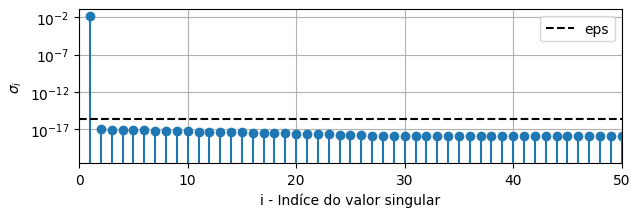

In [163]:
plt.figure(figsize=(7,2))
plt.stem(np.arange(len(s))+1,s)
plt.axhline(np.finfo(float).eps,color='black',ls='dashed',label='eps')
plt.xlabel('i - Indíce do valor singular')
plt.ylabel('$\\sigma_i$')
plt.yscale('log')
plt.xlim(0,50)
plt.legend()
plt.grid()

#### Montando a matriz de toeplitz
Definindo o operador $\mathrm{toep}$

In [164]:
def toep(arr,diag_idx):
    """
    Transforma array unidimensional em matriz de toeplitz, conforme convenção de
    Kamm, Nagy
    """
    if arr.ndim > 1:
        raise ValueError('`arr` há de ser unidimensional')
    arr_len = len(arr)
    output = np.zeros([arr_len,arr_len])
    for idx in range(output.shape[1]):
        idx_roll = idx-diag_idx
        arr_roll = np.roll(arr,idx_roll)
        clip_idx = np.max([0,idx_roll])
        arr_roll[:clip_idx] = 0
        output[:,idx] = arr_roll
    return output

Finalmente, recomputamos $\mathbf{A}$ e $\mathbf{B}$.
Em um mundo ideal:
- $\mathbf{A}_\mathrm{computado} = \mathbf{A}_\mathrm{dataset}$; e
- $\mathbf{B}_\mathrm{computado} = \mathbf{B}_\mathrm{dataset}$,

portanto
$$\mathbf{P}_\mathrm{computado}= \mathbf{P}_\mathrm{dataset}.$$

No entanto, observou-se um erro de 2% entre $\mathbf{P}_\mathrm{computado}$ e $\mathbf{P}_\mathrm{dataset}$. Essa diferença foi atribuida à instabilidade numérica e diferença entre implementações da SVD.

Erro(P_approx - P): 2.352 %


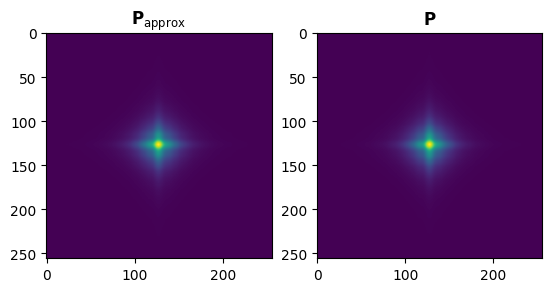

In [177]:
#Forçando u a ser positivo
if np.sum(u) < 0:
    u1 = -u
if np.sum(v) < 0:
    v1 = -v

a1 = np.sqrt(s[0])*u1[:,0]
b1 = np.sqrt(s[0])*v1[:,0]

A1 = toep(a1,mid_idx[0])
B1 = toep(b1,mid_idx[0])

P_approx = ( B1 @ F_delta ) @ A1.T
print(f"Erro(P_approx - P): {(norm(P - P_approx) / norm(P))*100:.3f} %", )

plt.subplot(1,2,1)
plt.title('$\\mathbf{P}_\\mathrm{approx}$')
plt.imshow(P_approx)
plt.subplot(1,2,2)
plt.title('$\\mathbf{P}$')
plt.imshow(P);

# plt.figure()
# plt.imshow(P-P_approx)

## Invertendo o problema
### removendo dependência de $\mathbf{K}$
$$
{\mathbf{g}} = \mathbf{K}{\mathbf{f}}\\

\implies {\mathbf{g}} = \mathbf{U}\Sigma \mathbf{V}^\mathrm{T} {\mathbf{f}}.
$$

Note que $\mathbf{U}$ e $\mathbf{V}$ são matrizes ortogonais, portanto $\mathbf{U}^{-1} =\mathbf{U}^{\mathrm{T}} $, permitindo separar a equação em
$$
\mathbf{U}^\mathrm{T}{\mathbf{g}} = \Sigma\mathbf{V}^\mathrm{T} \mathbf{f}.
$$

O problema, então se torna
$$
\hat{\mathbf g} = \Sigma\hat{\mathbf{f}},
$$
em que:
- $\hat{\mathbf{g}}=\mathbf{U}^\mathrm{T}{\mathbf{g}}$
- $\hat{\mathbf{f}}=\mathbf{V}^\mathrm{T}{\mathbf{f}}$

### Adaptando a regularização de thikonov
#### A norma da solução
Note que $\mathbf{V}$ é ortogonal, portanto, $\mathbf{V}^\mathrm{T}\mathbf{V}=\mathbf{I}$, e 
$$
||\mathbf{f}||_2^2 = 
\mathbf{f}^\mathrm{T}\mathbf{f} = 
\mathbf{f}^\mathrm{T}\underbrace{\mathbf{V}\mathbf{V}^\mathrm{T}}_{\mathbf{I}}\mathbf{f} = 
\hat{\mathbf{f}}^\mathrm{T}\hat{\mathbf{f}}=||\hat{\mathbf{f}}||_2^2.
$$
#### A norma do resíduo
Da mesma forma, o resíduo pode ser escrito como
$$
||\mathbf{g} - \mathbf{K}\mathbf{f}||_2^2 = ||\hat{\mathbf{g}}-\Sigma\hat{\mathbf{f}}||_2^2,
$$

#### A regularização de Tikhonov

e o método de Tikhonov pode ser escrito, então, como
$$
\mathbf{f}_\mathrm{sol} = \arg \min_{\mathbf{f}} (||\hat{\mathbf g} - \Sigma \hat{\mathbf{f}}||_2^2 + \alpha^2 ||\hat{\mathbf{f}}||_2^2).
$$
---

## Computando a solução ingênua
A solução por mínimos quadrados pode ser entendida como a solução de Tikhonov quando $\alpha=0$, portanto, a solução $\mathbf{f}_\mathrm{sol}$ é
$$
\mathbf{f}_\mathrm{sol} = \arg \min_{\mathbf{f}} (||\hat{\mathbf g} - \Sigma \hat{\mathbf{f}}||_2^2),
$$
em que:
- $\mathbf{g} = \mathrm{vec}(\mathbf{G})$, $\mathbf{f} = \mathrm{vec}(\mathbf{F})$
- $\hat{\mathbf{g}} = \mathbf{U}^\mathrm{T}\mathbf{g}$ 
- $\hat{\mathbf{f}} = \mathbf{V}^\mathrm{T}\mathbf{f}$
- $ \mathbf{K} = \mathbf{U}\Sigma \mathbf{V}^\mathrm{T} = (\mathbf{U}_A \otimes \mathbf{U}_B)(\Sigma_A \otimes \Sigma_B)(\mathbf{V}_A \otimes \mathbf{V}_B)^\mathrm{T} $

### Reaplicando a mesma propriedade
Note que $\mathbf{U}$ e $\mathbf{V}$ ainda são matrizes $n \times n$, permanecendo impossíveis de serem alocadas em um computador doméstico. A mesma propriedade que permite o cômputo do problema direto é aplicada ao problema inverso: 
$$
(\mathbf{L} \otimes \mathbf{R})\space\mathrm{vec}(\mathbf V) = \mathrm{vec}(\mathbf R\space \mathbf V\space \mathbf{ L}^\mathrm{T}),
$$
e portanto
$$
\hat{\mathbf{g}} = \mathrm{vec}(\overbrace{\mathbf{U}_B^\mathrm{T} \mathbf{G} \mathbf{U}_A}^{\hat{\mathbf{G}}})\text{, e}\\
\hat{\mathbf{f}} = \mathrm{vec}(\underbrace{\mathbf{V}_B^\mathrm{T} \mathbf{F} \mathbf{V}_A}_{\hat{\mathbf{F}}}).
$$
permitindo regularizar o problema com multiplicações entre matrizes de dimensões $\sqrt{n}\times\sqrt{n}$. No domínio de $\hat{\mathbf{G}}$ e $\hat{\mathbf{F}}$, os valores singulares podem ser incluidos por meio de um produto de hadamard ~~(não me pergunte como)~~
$$
\hat{\mathbf{F}} = \hat{\mathbf{G}}\odot (\Sigma_B \Sigma_A^\mathrm{T})^{-1}
$$

In [166]:
Ua,Sa,Va = np.linalg.svd(A,)
Va = Va.T
Ub,Sb,Vb = np.linalg.svd(B,)
Vb = Vb.T

Gh = ((Ub.T @ G) @ Ua)
gh = vec(Gh)

Ss = np.outer(Sb,Sa)

### O plot de picard
Como $\hat{\mathbf{G}}=\mathbf{U}^\mathrm{T}\mathbf{g}$, realizarei o plot de picard das colunas de $\hat{\mathbf{G}}$. Nesse contexto, $\left[\cdot\right]_{:,i}$ representa a $i$-ésima coluna da matriz.

Text(0, 0.5, 'Magnitude da $i$-ésima coluna')

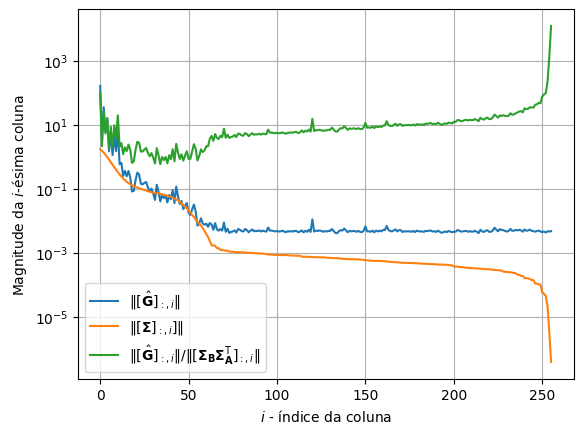

In [181]:
plt.plot(norm(Gh,axis=0),label='$\\|[\\hat{\\mathbf{G}}]_{:,i}\\|$')
plt.plot(norm(Ss,axis=0),label='$\\|[\\mathbf{\\Sigma}]_{:,i}]\\|$')
plt.plot(norm(Gh,axis=0)/norm(Ss,axis=0),label='$\\|[\\hat{\\mathbf{G}}]_{:,i}\\|/\\|[\\mathbf{\\Sigma_B \\Sigma_A^\\mathrm{T}}]_{:,i}\\|$')
plt.yscale('log')
plt.xlabel('$i$ - índice da coluna')
plt.legend()
plt.grid()
plt.ylabel('Magnitude da $i$-ésima coluna')

### A solução ingênua
Como
$$
\hat{\mathbf{F}} = \hat{\mathbf{G}}\odot (\Sigma_B \Sigma_A^\mathrm{T})^{-1},
$$
e simultâneamente
$$
\hat{\mathbf{F}} = \mathbf{V}_B^\mathrm{T} \mathbf{F} \mathbf{V}_A,
$$
podemos apenas transformar $\mathbf{V}_B$ e $\mathbf{V}_A$ em matrizes identidade por uma simples multiplicação de matrizes
$$
{\mathbf{F}} =\mathbf{V}_B \hat{\mathbf{F}}\mathbf{V}_A^\mathrm{T}= \underbrace{\mathbf{V}_B \mathbf{V}_B^\mathrm{T}}_{\mathbf{I}} \mathbf{F} \underbrace{\mathbf{V}_A \mathbf{V}_A^{\mathrm{T}}}_{\mathbf{I}},
$$

Note que deu bastante errado. Apresento também, sem dar muitos detalhes uma solução mais adequada, para fins de comparação.

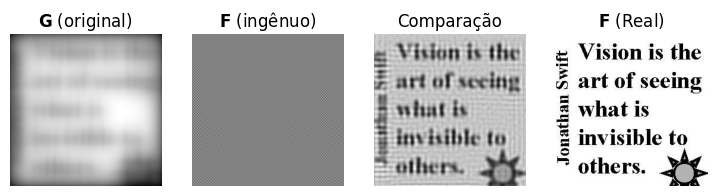

In [ ]:
Fh = Gh/Ss
F_naive = Vb @ Fh @ Va.T

F_sol = Vb @ (Gh*Ss/(Ss**2 + 1E-3**2)) @ Va.T

plt.figure(figsize=(9,4))
images = [G,F_naive,F_sol,F.T]
labels = ['$\\mathbf{G}$ (original)','$\\mathbf{F}$ (ingênuo)','Comparação','$\\mathbf{F}$ (Real)']
for idx,(lbl, matrix) in enumerate(zip(labels,images)):
    plt.subplot(1,4,idx+1)
    plt.title(lbl)
    plt.imshow(matrix.T,cmap='gray')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.gca().set_axis_off()